In [1]:
# 1. Import libraries and configure paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent

DATA_DIR = PROJECT_ROOT / "data" / "splits"

TRAIN_PATH = DATA_DIR / "train.csv"
VALIDATION_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"

In [2]:
# 2. Load train, validation, and test datasets

train_df = pd.read_csv(TRAIN_PATH, low_memory=False)
validation_df = pd.read_csv(VALIDATION_PATH, low_memory=False)
test_df = pd.read_csv(TEST_PATH, low_memory=False)

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

Training shape: (60957, 32)
Validation shape: (7618, 32)
Test shape: (7618, 32)

Training label distribution:
label
0    49866
1    11091
Name: count, dtype: int64


In [3]:
# 3. Create a sample corpus for Bag of Words

sample_messages = [
    "bank account verification",
    "bank account blocked",
    "money transfer completed"
]

sample_df = pd.DataFrame({
    "document": ["D1", "D2", "D3"],
    "text": sample_messages
})

display(sample_df)

,document,text
0,D1,bank account verification
1,D2,bank account blocked
2,D3,money transfer completed


In [4]:
# 4. Extract the vocabulary from sample documents

vocabulary = sorted(set(
    word
    for message in sample_messages
    for word in message.split()
))

print("Vocabulary size:", len(vocabulary))
print("Vocabulary:", vocabulary)

Vocabulary size: 7
Vocabulary: ['account', 'bank', 'blocked', 'completed', 'money', 'transfer', 'verification']


In [5]:
# 5. Generate the Bag of Words matrix

bow_vectorizer = CountVectorizer()

bow_matrix = bow_vectorizer.fit_transform(sample_messages)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out(),
    index=sample_df["document"]
)

display(bow_df)

,account,bank,blocked,completed,money,transfer,verification
document,,,,,,,
D1,1,1,0,0,0,0,1
D2,1,1,1,0,0,0,0
D3,0,0,0,1,1,1,0


In [6]:
# 6. Demonstrate that Bag of Words ignores word order

order_messages = [
    "bank account",
    "account bank"
]

order_matrix = bow_vectorizer.transform(order_messages)

order_df = pd.DataFrame(
    order_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out(),
    index=order_messages
)

display(order_df[["account", "bank"]])

,account,bank
bank account,1,1
account bank,1,1


In [7]:
# 7. Demonstrate repeated word counting

repeated_messages = [
    "bank bank account",
    "account money money"
]

repeated_matrix = bow_vectorizer.transform(repeated_messages)

repeated_df = pd.DataFrame(
    repeated_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out(),
    index=["D1", "D2"]
)

display(repeated_df)

,account,bank,blocked,completed,money,transfer,verification
D1,1,2,0,0,0,0,0
D2,1,0,0,0,2,0,0


In [8]:
# 8. Calculate sparsity of the sample BoW matrix

total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_elements = bow_matrix.nnz
zero_elements = total_elements - nonzero_elements

sparsity = (zero_elements / total_elements) * 100

print("Matrix shape:", bow_matrix.shape)
print("Total elements:", total_elements)
print("Non-zero elements:", nonzero_elements)
print("Zero elements:", zero_elements)
print(f"Sparsity: {sparsity:.2f}%")

Matrix shape: (3, 7)
Total elements: 21
Non-zero elements: 9
Zero elements: 12
Sparsity: 57.14%


In [9]:
# 9. Apply Bag of Words to the real training dataset

real_bow_vectorizer = CountVectorizer(
    max_features=10000,
    ngram_range=(1, 1)
)

X_train_bow = real_bow_vectorizer.fit_transform(
    train_df["normalized_text"].fillna("")
)

print("Document-term matrix shape:", X_train_bow.shape)
print("Vocabulary size:", len(real_bow_vectorizer.vocabulary_))
print("Non-zero elements:", X_train_bow.nnz)

Document-term matrix shape: (60957, 10000)
Vocabulary size: 10000
Non-zero elements: 4698934


In [10]:
# 10. Calculate sparsity of the real BoW matrix

total_elements = X_train_bow.shape[0] * X_train_bow.shape[1]
nonzero_elements = X_train_bow.nnz

sparsity = (
    (total_elements - nonzero_elements) / total_elements
) * 100

print(f"Total elements: {total_elements:,}")
print(f"Non-zero elements: {nonzero_elements:,}")
print(f"Zero elements: {total_elements - nonzero_elements:,}")
print(f"Sparsity: {sparsity:.2f}%")

Total elements: 609,570,000
Non-zero elements: 4,698,934
Zero elements: 604,871,066
Sparsity: 99.23%


In [11]:
# 11. Inspect the vocabulary learned by BoW

bow_vocabulary = real_bow_vectorizer.get_feature_names_out()

print("Total vocabulary terms:", len(bow_vocabulary))
print("\nFirst 50 vocabulary terms:")
print(bow_vocabulary[:50])

Total vocabulary terms: 10000

First 50 vocabulary terms:
['00' '000' '0000' '00000' '00000000' '000000000' '00000million' '001'
 '002' '003' '005' '00pm' '01' '0100' '02' '0200' '02139' '03' '04' '0400'
 '05' '0500' '06' '0600' '06033' '07' '0700' '08' '09' '0d' '0x' '10'
 '100' '1000' '10000' '100000' '10019' '10019help' '1002' '10020' '10022'
 '100k' '101' '102' '1024' '103' '104' '105' '106' '107']


In [12]:
# 12. Discover the full vocabulary without a feature limit

full_bow_vectorizer = CountVectorizer()

full_bow_vectorizer.fit(
    train_df["normalized_text"].fillna("")
)

full_vocabulary = full_bow_vectorizer.get_feature_names_out()

print("Full vocabulary size:", len(full_vocabulary))
print("\nFirst 50 vocabulary terms:")
print(full_vocabulary[:50])

Full vocabulary size: 115436

First 50 vocabulary terms:
['00' '000' '0000' '00000' '000000' '0000000' '00000000' '000000000'
 '00000000000000' '00000000000000000000000000000000' '0000000000001'
 '000000000001' '000000000445' '00000001' '0000000149011611938477'
 '00000003' '000000064' '00000010' '000000128' '000000196' '00000049'
 '0000005' '0000006hz' '000000e' '000000eb' '000000i' '000000t0000z'
 '000001' '0000010' '00000100' '00000101' '00000111' '00000201' '00000354'
 '0000040' '000005' '00000eur' '00000kt' '00000million' '00001' '00001000'
 '00002' '0000211' '00003071548037755724105' '00003759' '00004' '000055'
 '00006' '000060' '000064000']


In [13]:
# 13. Generate the full-vocabulary BoW matrix

full_bow_matrix = full_bow_vectorizer.transform(
    train_df["normalized_text"].fillna("")
)

print("Document-term matrix shape:", full_bow_matrix.shape)
print("Vocabulary size:", len(full_bow_vectorizer.vocabulary_))
print("Non-zero elements:", full_bow_matrix.nnz)
print("Matrix data type:", full_bow_matrix.dtype)

Document-term matrix shape: (60957, 115436)
Vocabulary size: 115436
Non-zero elements: 5052694
Matrix data type: int64


In [14]:
# 14. Analyze numeric and alphanumeric vocabulary terms

import re

pure_numeric = [
    word for word in full_vocabulary
    if re.fullmatch(r"\d+", word)
]

alphanumeric = [
    word for word in full_vocabulary
    if re.search(r"\d", word)
]

print("Full vocabulary:", len(full_vocabulary))
print("Pure numeric tokens:", len(pure_numeric))
print("Tokens containing digits:", len(alphanumeric))

print(
    f"Pure numeric percentage: "
    f"{len(pure_numeric) / len(full_vocabulary) * 100:.2f}%"
)

print(
    f"Tokens containing digits percentage: "
    f"{len(alphanumeric) / len(full_vocabulary) * 100:.2f}%"
)

Full vocabulary: 115436
Pure numeric tokens: 7933
Tokens containing digits: 19762
Pure numeric percentage: 6.87%
Tokens containing digits percentage: 17.12%


In [15]:
# 15. Analyze document frequency of numeric tokens

numeric_mask = np.array([
    bool(re.fullmatch(r"\d+", word))
    for word in full_vocabulary
])

numeric_indices = np.where(numeric_mask)[0]

numeric_document_frequency = np.asarray(
    (full_bow_matrix[:, numeric_indices] > 0).sum(axis=0)
).ravel()

numeric_frequency_df = pd.DataFrame({
    "token": full_vocabulary[numeric_indices],
    "document_frequency": numeric_document_frequency
})

print("Numeric vocabulary terms:", len(numeric_frequency_df))

print("\nDocument frequency distribution:")
display(numeric_frequency_df["document_frequency"].describe())

print("\nMost widespread numeric tokens:")
display(
    numeric_frequency_df.sort_values(
        "document_frequency", ascending=False
    ).head(20)
)

Numeric vocabulary terms: 7933

Document frequency distribution:


count    7933.000000
mean       11.978066
std        97.940001
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      4029.000000
Name: document_frequency, dtype: float64


Most widespread numeric tokens:


,token,document_frequency
984,10,4029
1,000,2166
2594,2007,2123
2540,20,2089
0,00,2034
4058,30,2020
1943,15,1926
1478,12,1915
1256,11,1712
985,100,1519


In [16]:
# 16. Compare numeric token prevalence across classes

top_numeric_tokens = (
    numeric_frequency_df
    .nlargest(20, "document_frequency")["token"]
    .tolist()
)

rows = []

for token in top_numeric_tokens:
    token_index = full_bow_vectorizer.vocabulary_[token]

    row = {"token": token}

    for label, class_name in [(0, "legitimate"), (1, "scam")]:
        class_mask = train_df["label"].to_numpy() == label

        present = (
            full_bow_matrix[class_mask, token_index] > 0
        ).sum()

        class_size = class_mask.sum()

        row[f"{class_name}_documents"] = int(present)
        row[f"{class_name}_prevalence_pct"] = round(
            present / class_size * 100, 2
        )

    rows.append(row)

numeric_class_comparison = pd.DataFrame(rows)

display(numeric_class_comparison)

,token,legitimate_documents,legitimate_prevalence_pct,scam_documents,scam_prevalence_pct
0,10,3089,6.19,940,8.48
1,000,649,1.30,1517,13.68
2,2007,2093,4.20,30,0.27
3,20,1551,3.11,538,4.85
4,00,735,1.47,1299,11.71
5,30,1385,2.78,635,5.73
6,15,1519,3.05,407,3.67
7,12,1653,3.31,262,2.36
8,11,1574,3.16,138,1.24
9,100,1043,2.09,476,4.29


In [17]:
# 17. Inspect the least frequent numeric tokens

print("Least frequent numeric tokens:")

display(
    numeric_frequency_df
    .sort_values("document_frequency")
    .head(30)
)

Least frequent numeric tokens:


,token,document_frequency
38,000055,1
7909,9953199347826,1
7908,9953,1
4894,41200,1
6595,6863,1
6591,68541491,1
7902,9934,1
7901,993352,1
7900,9931,1
7898,9920,1


In [18]:
# 18. Compare vocabulary sizes under different min_df thresholds

document_frequencies = np.asarray(
    (full_bow_matrix > 0).sum(axis=0)
).ravel()

min_df_values = [1, 2, 5, 10, 20, 50]

min_df_comparison = pd.DataFrame({
    "min_df": min_df_values,
    "remaining_features": [
        int((document_frequencies >= threshold).sum())
        for threshold in min_df_values
    ]
})

min_df_comparison["removed_features"] = (
    len(full_vocabulary) - min_df_comparison["remaining_features"]
)

display(min_df_comparison)

,min_df,remaining_features,removed_features
0,1,115436,0
1,2,59070,56366
2,5,28714,86722
3,10,18726,96710
4,20,12505,102931
5,50,7372,108064


In [19]:
# 19. Analyze vocabulary distribution by document frequency

frequency_bins = [
    0, 1, 5, 10, 20, 50, float("inf")
]

frequency_labels = [
    "1",
    "2–4",
    "5–9",
    "10–19",
    "20–49",
    "50+"
]

frequency_categories = pd.cut(
    document_frequencies,
    bins=frequency_bins,
    labels=frequency_labels
)

frequency_distribution = (
    pd.Series(frequency_categories)
    .value_counts(sort=False)
)

frequency_distribution_df = pd.DataFrame({
    "document_frequency_range": frequency_distribution.index.astype(str),
    "number_of_terms": frequency_distribution.values
})

frequency_distribution_df["percentage"] = (
    frequency_distribution_df["number_of_terms"]
    / len(full_vocabulary) * 100
).round(2)

display(frequency_distribution_df)

,document_frequency_range,number_of_terms,percentage
0,1,56366,48.83
1,2–4,33681,29.18
2,5–9,7690,6.66
3,10–19,5527,4.79
4,20–49,4887,4.23
5,50+,7285,6.31


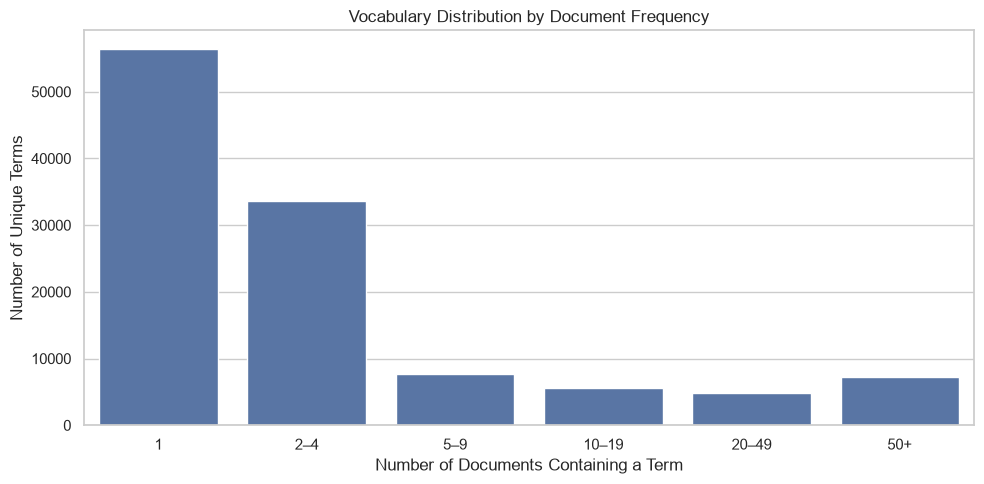

In [20]:
# 20. Visualize vocabulary distribution by document frequency

plt.figure(figsize=(10, 5))

sns.barplot(
    data=frequency_distribution_df,
    x="document_frequency_range",
    y="number_of_terms"
)

plt.title("Vocabulary Distribution by Document Frequency")
plt.xlabel("Number of Documents Containing a Term")
plt.ylabel("Number of Unique Terms")

plt.tight_layout()
plt.show()

In [22]:
# 21. Generate TF-IDF representation of the training dataset

tfidf_vectorizer = TfidfVectorizer(
    max_features=None,
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf_vectorizer.fit_transform(
    train_df["normalized_text"].fillna("")
)

print("TF-IDF matrix shape:", X_train_tfidf.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))
print("Non-zero elements:", X_train_tfidf.nnz)
print("Matrix data type:", X_train_tfidf.dtype)

TF-IDF matrix shape: (60957, 115436)
Vocabulary size: 115436
Non-zero elements: 5052694
Matrix data type: float64


In [23]:
# 22. Compare BoW and TF-IDF values for one training message

sample_index = 0

bow_row = full_bow_matrix[sample_index]
tfidf_row = X_train_tfidf[sample_index]

comparison = pd.DataFrame({
    "word": full_bow_vectorizer.get_feature_names_out(),
    "BoW_count": bow_row.toarray().ravel(),
    "TF_IDF_weight": tfidf_row.toarray().ravel()
})

comparison = comparison[
    comparison["BoW_count"] > 0
].sort_values("TF_IDF_weight", ascending=False)

print("Message:")
print(train_df.iloc[sample_index]["normalized_text"][:500])

display(comparison.head(20))

Message:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA.
CONFIDENTIAL TEL: [PHONE_NUMBER].
E-MAIL: ([EMAIL_ADDRESS]).

URGENT BUSINESS ASSISTANCE AND PARTNERSHIP.


DEAR FRIEND,

I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CONGOLESE (PRESIDENT LAURENT KABILA) WHO WAS ASSASSINATED BY HIS BODY GUARD ON 16TH JAN. 2001.


THE INCIDENT OCCURRED IN OUR PRESENCE WHILE WE WERE HOLDING MEETING WITH HIS EXCELLENCY OVER THE FINANCIAL RETURNS FROM THE DIAMOND SALES IN THE AREAS CONT


,word,BoW_count,TF_IDF_weight
103225,the,40,0.309245
72620,ngola,3,0.197866
5957,25m,3,0.174322
75028,of,19,0.173085
114640,your,15,0.171139
55814,in,18,0.166404
19629,assistance,6,0.158450
104521,to,20,0.151691
19290,as,12,0.148138
30864,congo,3,0.146526


In [24]:
# 23. Inspect inverse document frequency scores

idf_values = tfidf_vectorizer.idf_
feature_names = tfidf_vectorizer.get_feature_names_out()

idf_df = pd.DataFrame({
    "word": feature_names,
    "IDF": idf_values
})

selected_words = [
    "the", "account", "bank", "money",
    "ngola", "25m", "congo", "diplomatic"
]

display(
    idf_df[idf_df["word"].isin(selected_words)]
    .sort_values("IDF", ascending=False)
)

,word,IDF
72620,ngola,10.919328
5957,25m,9.620045
30864,congo,8.086115
37219,diplomatic,6.797585
21419,bank,3.992751
69505,money,3.976206
14829,account,3.288220
103225,the,1.279936


In [27]:
# 24. Inspect terms with the highest IDF scores

highest_idf = (
    idf_df
    .sort_values("IDF", ascending=False)
    .head(30)
)

display(highest_idf)

,word,IDF
9,00000000000000000000000000000000,11.324793
115435,퓸求,11.324793
115434,주소를,11.324793
115433,이메일주소로,11.324793
115432,새로운,11.324793
115431,보내주세요,11.324793
115430,메일을,11.324793
5,0000000,11.324793
10,0000000000001,11.324793
115413,尽在亿邮短信,11.324793


In [28]:
# 25. Trace suspicious vocabulary to source messages

suspicious_terms = [
    "주소를",
    "外国货也超便宜",
    "足球大富翁",
    "string_substr",
    "00000000000000000000000000000000"
]

for term in suspicious_terms:
    matches = train_df[
        train_df["normalized_text"].str.contains(
            re.escape(term),
            na=False,
            regex=True
        )
    ]

    print(f"\nTerm: {term}")
    print("Matching records:", len(matches))

    display(
        matches[
            ["record_id", "label", "channel", "source", "normalized_text"]
        ].head(2)
    )


Term: 주소를
Matching records: 1


,record_id,label,channel,source,normalized_text
1661,FIN-02099,1,email,Nigerian_Fraud.csv,Confidential and urgent 새로운 메일 주소를 갖게 되었습니다!다음 이메일주소로 메일을 보내주세요:[EMAIL_ADDRESS]\n\n>From Desk:Mr...



Term: 外国货也超便宜
Matching records: 1


,record_id,label,channel,source,normalized_text
2140,FIN-02674,1,email,Nigerian_Fraud.csv,"URGENT REPLY. Hello Sir,\r\nI got your contact email address through a personal search and decid..."



Term: 足球大富翁
Matching records: 1


,record_id,label,channel,source,normalized_text
2140,FIN-02674,1,email,Nigerian_Fraud.csv,"URGENT REPLY. Hello Sir,\r\nI got your contact email address through a personal search and decid..."



Term: string_substr
Matching records: 1


,record_id,label,channel,source,normalized_text
60668,MEAJOR-LEG-057294,0,email,MeAJOR (trec7),"Re: [perl #43481] t/examples/shootout.t (shootout_16.pir) fails on gentoo/x86\n\nOn Tue, [DATE_T..."



Term: 00000000000000000000000000000000
Matching records: 2


,record_id,label,channel,source,normalized_text
53264,MEAJOR-LEG-048034,0,email,MeAJOR (trec7),svn commit: samba r[IDENTIFIER] - in branches/SAMBA_4_0/source/dsdb/schema: .\n\nAuthor: [PERSON...
59336,MEAJOR-LEG-055636,0,email,MeAJOR (trec7),[CTDB and GFS] some troubles joining domain\n\nI'm building a cluster with CTDB and <|FILE|> wit...


In [29]:
# 26. Measure non-ASCII character prevalence

text_series = train_df["normalized_text"].fillna("")

non_ascii_records = text_series.str.contains(r"[^\x00-\x7F]", regex=True)

print("Total training records:", len(train_df))
print("Records containing non-ASCII characters:", non_ascii_records.sum())
print(
    "Percentage:",
    round(non_ascii_records.mean() * 100, 2),
    "%"
)

print("\nBreakdown by class:")
display(
    train_df.assign(has_non_ascii=non_ascii_records)
    .groupby("label")["has_non_ascii"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum": "records_with_non_ascii", "count": "total_records", "mean": "proportion"})
    .assign(proportion=lambda x: (x["proportion"] * 100).round(2))
)

Total training records: 60957
Records containing non-ASCII characters: 2438
Percentage: 4.0 %

Breakdown by class:


,records_with_non_ascii,total_records,proportion
label,,,
0,1449,49866,2.91
1,989,11091,8.92


In [30]:
# 27. Inspect non-ASCII character distribution

from collections import Counter
import unicodedata

non_ascii_chars = Counter(
    char
    for text in train_df["normalized_text"].fillna("")
    for char in text
    if ord(char) > 127
)

character_report = pd.DataFrame([
    {
        "character": char,
        "unicode_name": unicodedata.name(char, "UNKNOWN"),
        "unicode_category": unicodedata.category(char),
        "frequency": count
    }
    for char, count in non_ascii_chars.most_common(40)
])

display(character_report)

,character,unicode_name,unicode_category,frequency
0,Ã,LATIN CAPITAL LETTER A WITH TILDE,Lu,5902
1,Â,LATIN CAPITAL LETTER A WITH CIRCUMFLEX,Lu,5333
2,â,LATIN SMALL LETTER A WITH CIRCUMFLEX,Ll,2303
3,¢,CENT SIGN,Sc,2196
4,,NO-BREAK SPACE,Zs,1276
5,¬,NOT SIGN,Sm,1176
6,é,LATIN SMALL LETTER E WITH ACUTE,Ll,979
7,Æ,LATIN CAPITAL LETTER AE,Lu,912
8,¡,INVERTED EXCLAMATION MARK,Po,611
9,,UNKNOWN,Cc,610
